# Example calculation of segmental Legendre order parameter (P1)

In [1]:
from vast_pea.lammps_segments import segment
from vast_pea.computers import compute_legendre_poly

import matplotlib.pyplot as plt
from matplotlib import colormaps
colormap = 'plasma'
cmap = colormaps.get_cmap(colormap).resampled(10) # colormap for plotting multiple temperatures. Using a higher number than the number of temperatures (8) skips the really light yellow colors

## Calculate the segment orientation autocorrelation function (P1)

In [2]:
# start by reading/restoring a segment object
seg = segment(traj=None, # we can set the traj, mass_list and identifiers argument can be set to None while restoring
              mass_list=None,
              identifiers=None,
              restore=True, # we are restoring from saved files
              restore_path="../../data/BER/save/",
              restore_pattern="afd_325K.segment_data.*.nc", # pattern matching the saved netCDF files
              verbose=True # print
              )

p1 = compute_legendre_poly(vectors=seg.get_vectors().vector, # DataArray of vector components for segments
                             order=1 # order of the Legendre polynomial. Only 1 and 2 are implemented currently
                             )
p1

	Calculating segments!


array([1.        , 0.9999139 , 0.9997592 , 0.9976536 , 0.9909184 ,
       0.9896502 , 0.9844193 , 0.9792008 , 0.96469796, 0.956528  ,
       0.94907117, 0.9345078 , 0.9233429 , 0.9194092 , 0.91602665],
      dtype=float32)

## Plot P1

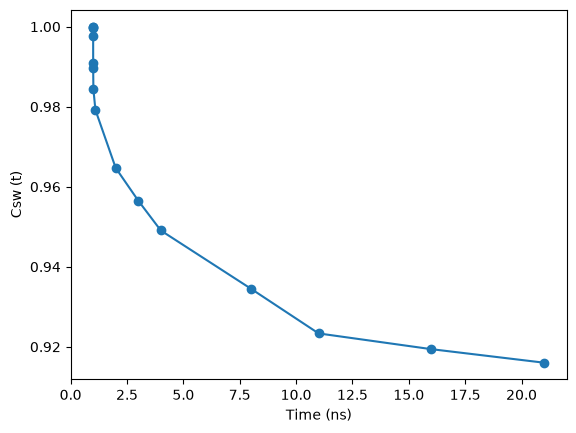

In [3]:
plt.plot(seg.timesteps/1e6, p1, 'o-')
plt.xlabel("Time (ns)")
plt.ylabel("Csw (t)")
plt.show()

## Plot all temperatures in log xscale

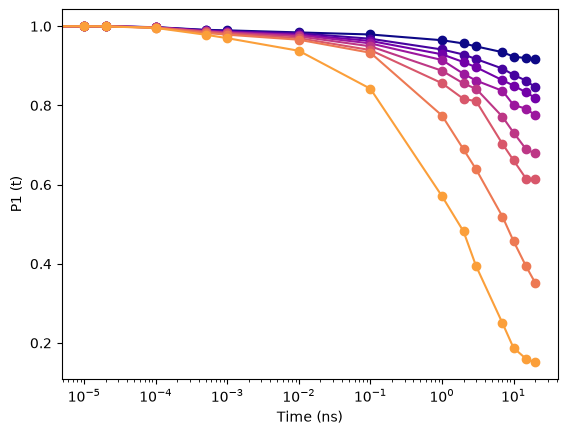

In [4]:
temperatures = [
    '325K',
    '350K',
    '375K',
    '400K',
    '425K',
    '450K',
    '500K',
    '600K'
]

for i, t in enumerate(temperatures):
    seg = segment(traj=None, mass_list=None, identifiers=None,
                  restore=True,
                  restore_path="../../data/BER/save/",
                  restore_pattern="afd_{}.segment_data.*.nc".format(t),
                  verbose=False
                  )

    time = seg.timesteps / 1e6 - 1 # -1 since the BER part starts at 1ns after equilibration
    p1 = compute_legendre_poly(seg.get_vectors().vector, 1)

    plt.plot(time, p1, 'o-', c=cmap(i), label=t)

plt.xscale('log')
plt.xlabel("Time (ns)")
plt.ylabel("P1 (t)")
plt.show()